In [16]:
# ============================================================
# TÌM HIỂU BỘ DỮ LIỆU HÀNH VI MÃ ĐỘC - MalBehavD-V1
# ============================================================

# 1. IMPORT THƯ VIỆN
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from statsmodels.stats.outliers_influence import variance_inflation_factor
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')


In [17]:
# 2. LOAD DATASET
df_raw = pd.read_csv(Path.cwd() / "Dataset" / "MalBehavD-V1-dataset.csv")

print("Shape:", df_raw.shape)

print("\nLabel distribution:")
print(df_raw['labels'].value_counts())

print("\n5 dòng đầu tiên:")
print(df_raw.head())

Shape: (2570, 177)

Label distribution:
labels
0    1285
1    1285
Name: count, dtype: int64

5 dòng đầu tiên:
                                              sha256  labels  \
0  5c18291c481a192ed5003084dab2d8a117fd3736359218...       0   
1  4683faf3da550ffb594cf5513c4cbb34f64df85f27fd1c...       0   
2  9a0aea1c7290031d7c3429d0e921f107282cc6eab854ee...       0   
3  e0f3e4d5f50afd9c31e51dd9941c5a52d57c7c524f5d11...       0   
4  ec2b6d29992f13e74015ff0b129150b4afae15c593e4b7...       0   

                     0                        1                   2  \
0         LdrUnloadDll           CoUninitialize          NtQueryKey   
1         NtOpenMutant      GetForegroundWindow          NtQueryKey   
2  GetForegroundWindow              DrawTextExW       GetSystemInfo   
3      NtQueryValueKey             LdrUnloadDll  GlobalMemoryStatus   
4         LdrUnloadDll  GetSystemTimeAsFileTime           NtOpenKey   

                   3                            4                       5  \


In [18]:
# 3. CHUYỂN API CALL -> BINARY FEATURE
api_cols = [c for c in df_raw.columns if c != 'labels']
all_apis = set()
for col in api_cols:
    all_apis.update(df_raw[col].dropna().unique())
all_apis = sorted(all_apis)
api2idx = {api: i for i, api in enumerate(all_apis)}
X_bin = np.zeros((len(df_raw), len(all_apis)), dtype=np.int8)
for i, row in df_raw.iterrows():
    for col in api_cols:
        api = row[col]
        if pd.notna(api):
            X_bin[i, api2idx[api]] = 1
df = pd.DataFrame(X_bin, columns=all_apis)
df['labels'] = df_raw['labels'].values
print("\nBinary dataset shape:", df.shape)



Binary dataset shape: (2570, 2835)


In [19]:
# 4. KIỂM TRA NaN
print("\nNaN count:", df.isnull().sum().sum())

# 5. TÁCH X, y
X = df.drop('labels', axis=1)
y = df['labels']
print("X shape:", X.shape, "y shape:", y.shape)

# 6. CHUẨN HÓA
scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# 7. THỐNG KÊ CƠ BẢN
print("\nDescriptive statistics:\n", X_scaled.describe())



NaN count: 0
X shape: (2570, 2834) y shape: (2570,)



Descriptive statistics:
        001300a5323bf6c1812b686c1c896857d4cf85c676e48f451d8cb7b9a8f0afe0  \
count                                        2570.000000                  
mean                                            0.000389                  
std                                             0.019726                  
min                                             0.000000                  
25%                                             0.000000                  
50%                                             0.000000                  
75%                                             0.000000                  
max                                             1.000000                  

       001a9515fe0cb67fa49d200b330311b65822287bd2d1bff8c78247176781f131  \
count                                        2570.000000                  
mean                                            0.000389                  
std                                             0.019726                 

In [20]:
# 8. TOP API FREQUENCY
api_freq = X.sum().sort_values(ascending=False)
print("\nTop 20 APIs:\n", api_freq.head(20))



Top 20 APIs:
 NtClose                    2524
NtQueryValueKey            2447
NtOpenKey                  2446
LdrGetProcedureAddress     2324
NtCreateFile               2181
NtAllocateVirtualMemory    2173
LdrUnloadDll               2139
RegCloseKey                1936
LdrGetDllHandle            1922
LdrLoadDll                 1894
NtFreeVirtualMemory        1891
GetSystemTimeAsFileTime    1796
NtReadFile                 1596
NtTerminateProcess         1544
NtMapViewOfSection         1539
NtCreateSection            1473
NtWriteFile                1455
RegOpenKeyExW              1433
RegQueryValueExW           1339
GetFileAttributesW         1338
dtype: int64


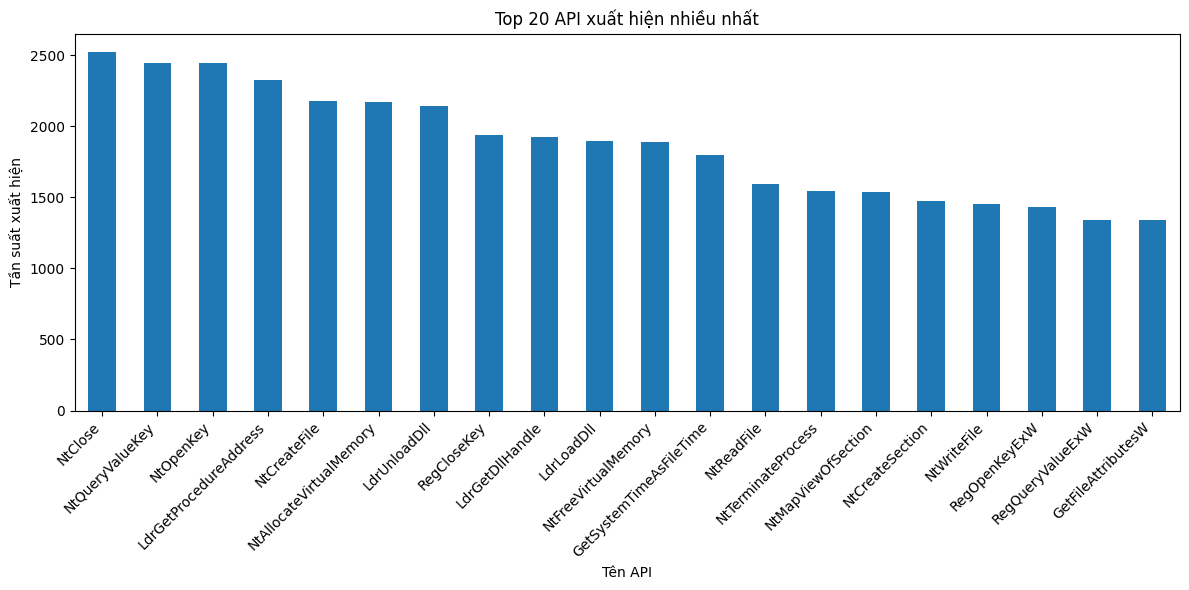

In [27]:
# 9. TRỰC QUAN HÓA CÁC API XUẤT HIỆN NHIỀU NHẤT
plt.figure(figsize=(12, 6))

api_freq.head(20).plot(kind='bar')

plt.title("Top 20 API xuất hiện nhiều nhất")
plt.xlabel("Tên API")
plt.ylabel("Tần suất xuất hiện")

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

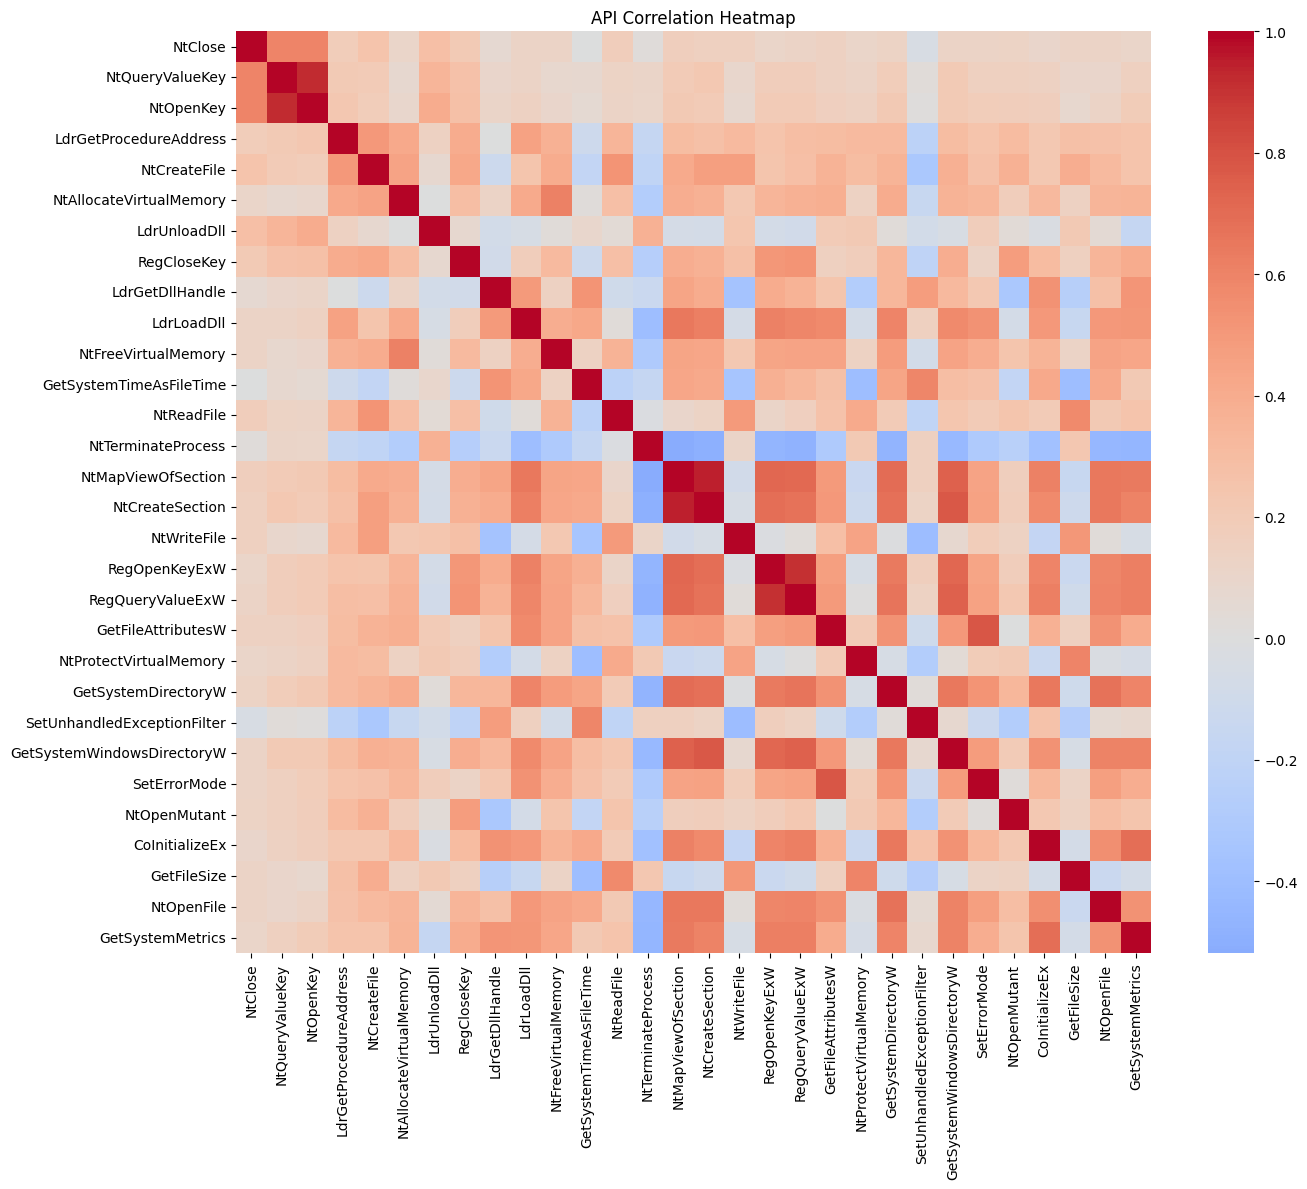

In [22]:
# 10. HEATMAP TƯƠNG QUAN (chỉ 30 API top)
top_features = api_freq.head(30).index
corr_matrix = X_scaled[top_features].corr()
plt.figure(figsize=(14,12))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0)
plt.title("API Correlation Heatmap")
plt.tight_layout()
plt.show()

In [23]:
# 11. RANDOM FOREST FEATURE IMPORTANCE
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_scaled, y)
importance_df = pd.DataFrame({'Feature': X_scaled.columns, 'Importance': rf.feature_importances_})
importance_df = importance_df.sort_values('Importance', ascending=False)
print("\nTop 20 important features:\n", importance_df.head(20))


Top 20 important features:
                           Feature  Importance
1554                  NtWriteFile    0.048956
1376       CreateProcessInternalW    0.044383
1608  SetUnhandledExceptionFilter    0.042520
1449      GetSystemTimeAsFileTime    0.032409
1433                  GetFileSize    0.031385
1369                    CopyFileA    0.029756
1567              RegCreateKeyExA    0.026098
1543                   NtReadFile    0.025754
1533       NtProtectVirtualMemory    0.022931
1365               CoInitializeEx    0.018176
1584               RegSetValueExA    0.015490
1487            IsDebuggerPresent    0.014129
1488              LdrGetDllHandle    0.013653
1529                 NtOpenMutant    0.012913
1381     CreateToolhelp32Snapshot    0.012780
1372                CreateActCtxW    0.012437
1403                  DrawTextExW    0.012056
1630                __exception__    0.012049
1445          GetSystemDirectoryA    0.011671
1410             FindFirstFileExW    0.010137


In [24]:
# 12. VIF ANALYSIS (top 20 features)
vif_features = importance_df.head(20)['Feature']
X_vif = X_scaled[vif_features]
vif_data = pd.DataFrame({'Feature': X_vif.columns})
vif_data['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
vif_data = vif_data.sort_values('VIF', ascending=False)
print("\nVIF Analysis:\n", vif_data)


VIF Analysis:
                         Feature       VIF
10               RegSetValueExA  8.424735
12              LdrGetDllHandle  8.255907
3       GetSystemTimeAsFileTime  7.948776
6               RegCreateKeyExA  7.735150
0                   NtWriteFile  6.814286
7                    NtReadFile  6.250040
16                  DrawTextExW  5.901821
9                CoInitializeEx  5.241097
1        CreateProcessInternalW  4.945761
4                   GetFileSize  4.605537
13                 NtOpenMutant  4.506855
18          GetSystemDirectoryA  4.392185
15                CreateActCtxW  4.310982
5                     CopyFileA  4.097192
2   SetUnhandledExceptionFilter  4.095401
8        NtProtectVirtualMemory  3.805923
19             FindFirstFileExW  2.696064
11            IsDebuggerPresent  2.240677
14     CreateToolhelp32Snapshot  1.906747
17                __exception__  1.882964


In [25]:

# 13. PHÁT HIỆN CẶP API TƯƠNG QUAN CAO
corr_abs = corr_matrix.abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
top_corr = upper.stack().sort_values(ascending=False)
print("\nTop correlated API pairs (corr > 0.8):\n", top_corr[top_corr > 0.8])


Top correlated API pairs (corr > 0.8):
 NtMapViewOfSection  NtCreateSection     0.948436
NtQueryValueKey     NtOpenKey           0.919202
RegOpenKeyExW       RegQueryValueExW    0.905482
dtype: float64


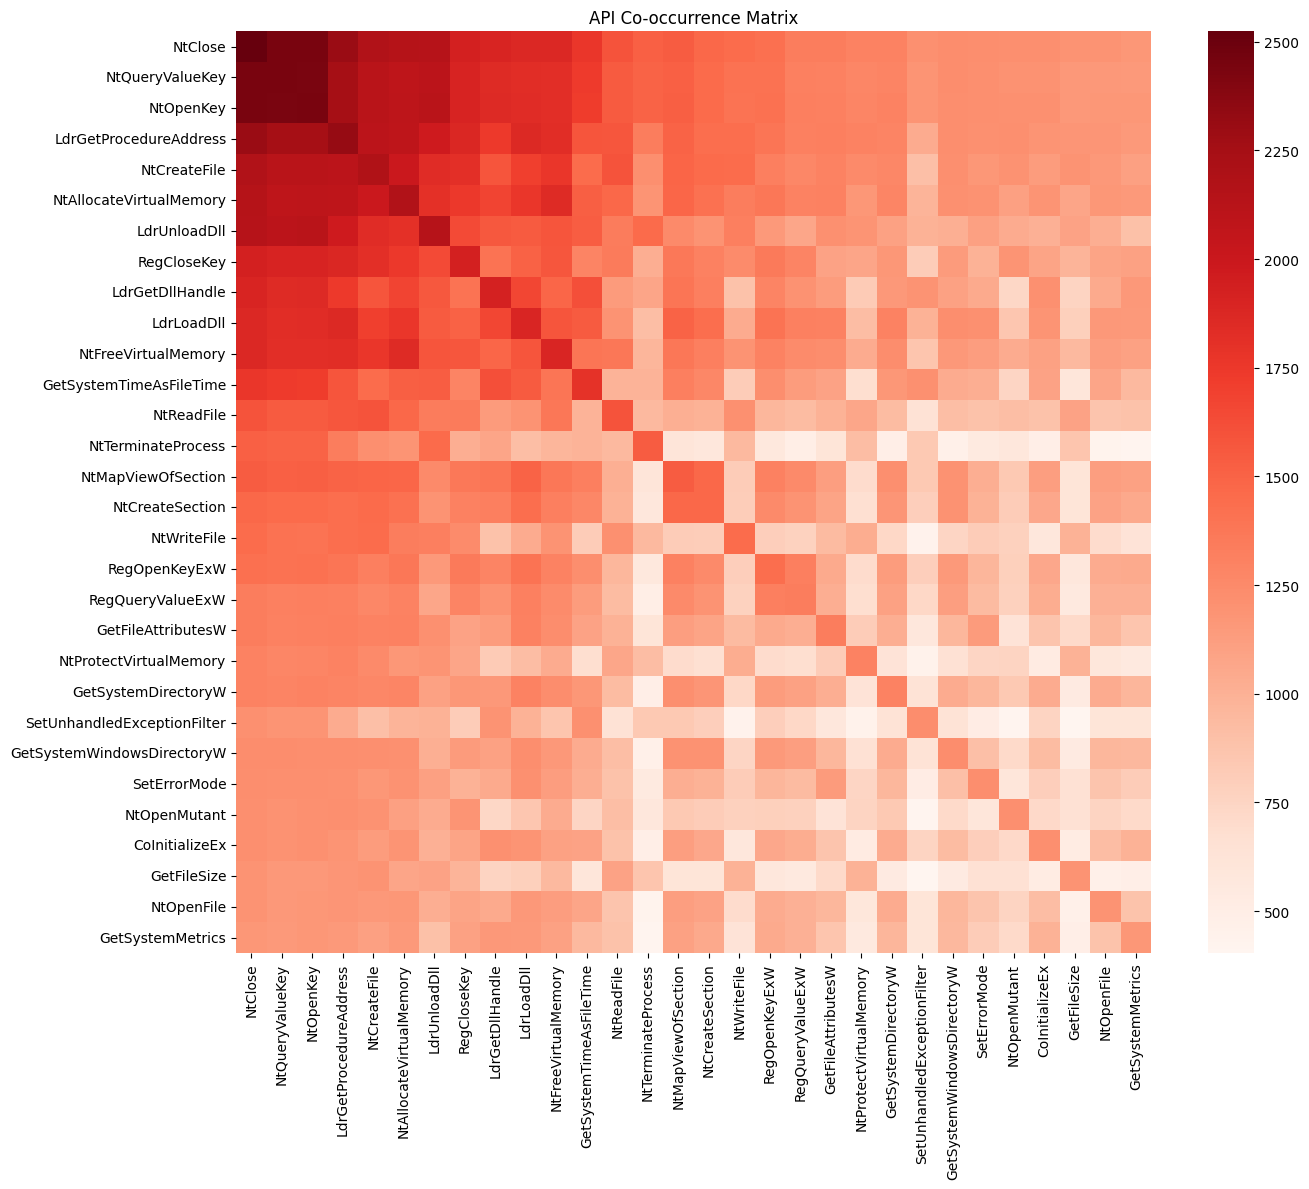

In [26]:

# 14. MA TRẬN ĐỒNG XUẤT HIỆN (co-occurrence)
co_matrix = np.dot(X_scaled[top_features].T, X_scaled[top_features])
co_df = pd.DataFrame(co_matrix, index=top_features, columns=top_features)
plt.figure(figsize=(14,12))
sns.heatmap(co_df, cmap='Reds')
plt.title("API Co-occurrence Matrix")
plt.tight_layout()
plt.show()